# CDS 303 - Project 0: Dataset Exploration

# Team members 
-Donghyeok Kim
-Dongjun Lee

## Dataset
- Name: Inside Airbnb – New York City Listings
- Source: Inside Airbnb (http://insideairbnb.com/get-the-data/)

## Description
This dataset contains listing-level information for Airbnb rentals in New York City,
including prices, room types, locations, and review activity. Each row is one listing.

In [11]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# data mining
from sklearn.decomposition import PCA

# visualization
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import warnings
warnings.filterwarnings(action = 'ignore')

In [12]:
import pandas as pd

df = pd.read_csv("listings.csv")
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,2992450,Luxury 2 bedroom apartment,4621559,1462661762635155041,Kenneth,NaN,THIRD WARD,42.65789,-73.75370,Entire home/apt,66.0,28.0,9,2022-08-17,0.06,1,169,0,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,1463087024016718788,Ming,NaN,SIXTH WARD,42.65222,-73.76724,Entire home/apt,171.0,1.0,320,2026-09-07,2.17,7,342,9,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,1463087024016718788,Ming,NaN,SIXTH WARD,42.65222,-73.76724,Entire home/apt,242.0,1.0,344,2026-09-07,2.50,7,337,12,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,1465431505328745177,Gregg,NaN,SECOND WARD,42.64734,-73.75851,Private room,79.0,1.0,479,2026-09-04,3.70,1,250,46,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,1462687000374947891,Elizabeth,NaN,FOURTEENTH WARD,42.66078,-73.80553,Private room,50.0,1.0,941,2026-08-30,7.28,2,142,100,NaN


In [13]:
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")

Rows: 500, Columns: 19


In [14]:
df.columns.tolist()

['id',
 'name',
 'host_id',
 'host_profile_id',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365',
 'number_of_reviews_ltm',
 'license']

In [15]:
df.dtypes

id                                  int64
name                               object
host_id                             int64
host_profile_id                     int64
host_name                          object
neighbourhood_group               float64
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                             float64
minimum_nights                    float64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                           float64
dtype: object

In [16]:
df.describe()

,id,host_id,host_profile_id,neighbourhood_group,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
count,5.000000e+02,5.000000e+02,5.000000e+02,0.0,500.000000,500.000000,467.000000,499.000000,500.000000,449.000000,500.000000,500.000000,500.000000,0.0
mean,9.883705e+17,2.412574e+16,1.480443e+18,NaN,42.659122,-73.777987,292.646681,6.793587,60.502000,1.753519,7.420000,251.638000,12.768000,NaN
std,5.942214e+17,2.027301e+17,4.985197e+16,NaN,0.010519,0.018357,1193.136679,19.584424,112.369586,1.878271,7.911307,122.494509,19.259908,NaN
min,2.992450e+06,6.490680e+05,1.462518e+18,NaN,42.630660,-73.876490,30.000000,1.000000,0.000000,0.040000,1.000000,0.000000,0.000000,NaN
25%,7.042966e+17,5.143576e+07,1.463574e+18,NaN,42.653118,-73.789317,89.000000,1.000000,3.000000,0.350000,2.000000,155.750000,1.000000,NaN
50%,1.120956e+18,2.117414e+08,1.468352e+18,NaN,42.657900,-73.776722,144.000000,2.000000,19.000000,1.150000,4.000000,313.000000,4.000000,NaN
75%,1.477201e+18,4.667901e+08,1.470110e+18,NaN,42.665579,-73.764730,209.000000,4.000000,68.500000,2.510000,11.000000,355.000000,17.000000,NaN
max,1.773591e+18,1.767798e+18,1.767798e+18,NaN,42.714900,-73.738250,11680.000000,365.000000,1006.000000,10.540000,31.000000,365.000000,116.000000,NaN


In [17]:
df.isnull().sum()

id                                  0
name                                0
host_id                             0
host_profile_id                     0
host_name                           0
neighbourhood_group               500
neighbourhood                       0
latitude                            0
longitude                           0
room_type                           0
price                              33
minimum_nights                      1
number_of_reviews                   0
last_review                        51
reviews_per_month                  51
calculated_host_listings_count      0
availability_365                    0
number_of_reviews_ltm               0
license                           500
dtype: int64

## Initial Observations
- About one third of listings (9,903) have no price value, which will need handling before any price analysis.
- `last_review` and `reviews_per_month` are missing for the same 8,309 listings — these are listings with zero reviews.
- The median minimum stay is 30 nights, likely reflecting NYC's short-term rental regulations.
- Prices are heavily right-skewed (median $175 vs. max $31,211), so median is a better summary than mean.

In [18]:
NYC = df[['latitude', 'longitude', 'price', 'minimum_nights',
          'number_of_reviews', 'reviews_per_month',
          'calculated_host_listings_count', 'availability_365',
          'number_of_reviews_ltm']].dropna()

NYC.shape


(420, 9)

In [19]:
NYC_st = StandardScaler().fit_transform(NYC)
NYC_st = pd.DataFrame(NYC_st, columns = NYC.columns)
NYC_st.head(10)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
0,-0.138578,1.327077,-0.202168,2.568565,-0.509498,-0.921917,-0.833689,-0.781036,-0.737548
1,-0.687508,0.588613,-0.071498,-0.390347,2.106896,0.202920,-0.092371,0.741108,-0.287155
2,-0.687508,0.588613,0.016860,-0.390347,2.308805,0.378842,-0.092371,0.697115,-0.137024
3,-1.159955,1.064742,-0.185990,-0.390347,3.444538,1.018560,-0.833689,-0.068356,1.564459
4,0.141211,-1.499700,-0.222080,-0.390347,7.331272,2.927052,-0.710136,-1.018596,4.266815
5,1.582756,-2.527768,0.041749,-0.390347,1.425456,0.064314,0.031182,0.793899,0.763761
6,1.598246,-0.269292,-0.215857,1.143904,1.358153,0.026998,-0.710136,0.934675,-0.737548
7,-0.753340,0.510622,-0.204657,0.048011,-0.332828,-0.735333,-0.710136,0.107614,-0.687504
8,1.006719,-2.699567,0.106462,-0.280757,1.122594,-0.084953,-0.833689,0.626727,-0.237111
9,-0.199570,-0.226751,-0.228302,1.472672,-0.122507,-0.714009,-0.710136,-0.605066,-0.687504


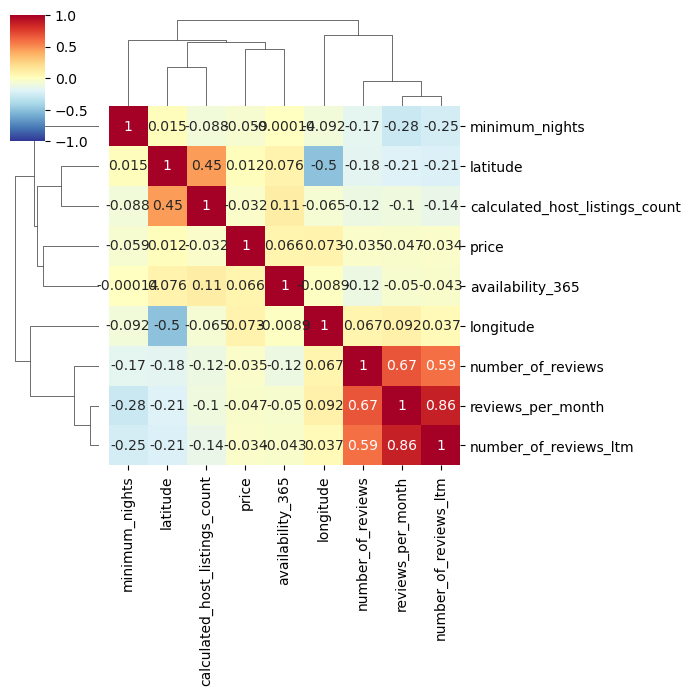

In [20]:
cor = NYC_st.corr()

sns.clustermap(cor, annot = True, cmap = 'RdYlBu_r',vmin = -1, vmax = 1,figsize=(7,7),)
plt.show()

In [21]:
pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(NYC_st)

array([[-1.20549042, -2.15090642, -1.31338548, ..., -0.0366344 ,
         0.95941482, -0.12635375],
       [ 1.28409385, -0.263147  ,  0.52524093, ...,  1.87176117,
        -0.45949847,  0.01677716],
       [ 1.55770296, -0.17472013,  0.52487615, ...,  1.90533864,
        -0.45944711,  0.02524577],
       ...,
       [-2.10424884,  2.56144992,  1.33790983, ...,  0.03119469,
         0.04461682, -0.02285919],
       [-0.50891379, -0.05503264, -0.29555635, ..., -0.03511681,
         0.19378192,  0.61518854],
       [ 0.07897334, -1.33665454, -0.19386999, ..., -0.16702927,
         0.23073187,  0.56535372]], shape=(420, 9))

In [22]:
pca.explained_variance_

array([2.7144324 , 1.57505219, 1.16370872, 0.96470373, 0.94154064,
       0.75657553, 0.43449157, 0.34666797, 0.12430696])

In [23]:
pca.explained_variance_ratio_

array([0.3008855 , 0.17458912, 0.12899311, 0.10693409, 0.10436654,
       0.0838638 , 0.0481619 , 0.03842695, 0.013779  ])

In [24]:
exp_variance_ratio = pca.explained_variance_ratio_

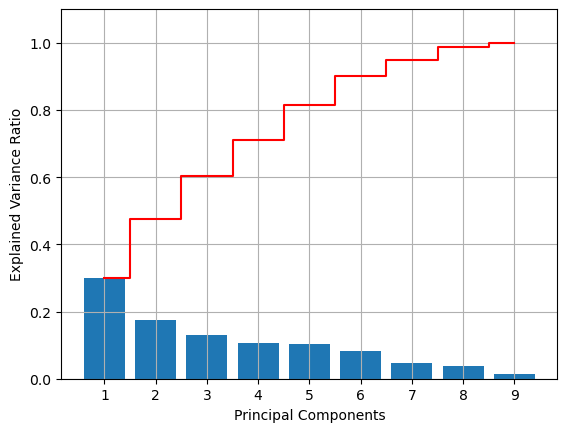

In [25]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1, len(exp_variance_ratio)+1)
    plt.bar(x_axis, exp_variance_ratio,
            align = 'center', label = 'Individual Explained Variance Ratio')
    plt.step(x_axis, np.cumsum(exp_variance_ratio),
             where = 'mid', color='red', label='Cumulative Explained Variance Ratio')
    plt.ylim(0, 1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.grid()
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

In [26]:
loadings = pca.components_

In [27]:
num_pc = pca.components_.shape[1]
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]

loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = NYC.columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
variable,,,,,,,,,
latitude,-0.282843,0.604731,-0.037993,0.095768,-0.110434,0.064528,0.129722,0.713834,-0.030663
longitude,0.160888,-0.497527,0.413173,-0.410730,-0.016216,0.337975,0.066548,0.514687,-0.057876
price,-0.022878,-0.083344,0.515359,0.705050,-0.409796,0.229969,-0.047950,-0.080402,0.016037
minimum_nights,-0.214325,-0.206433,-0.462228,0.284063,0.354568,0.688406,-0.121798,0.043206,0.027934
number_of_reviews,0.474863,0.161567,-0.107260,0.067613,-0.006467,0.254338,0.793291,-0.137625,-0.139079
reviews_per_month,0.547530,0.212834,0.006021,0.036252,0.086570,0.096539,-0.252531,0.114798,0.748196
calculated_host_listings_count,-0.184766,0.463397,0.319037,-0.438894,-0.055130,0.507071,-0.142632,-0.419258,-0.020771
availability_365,-0.090486,0.102501,0.484315,0.188039,0.819426,-0.147434,0.134603,-0.006729,-0.005273
number_of_reviews_ltm,0.529193,0.201399,-0.026623,0.102320,0.108888,0.044208,-0.479651,0.096260,-0.644262


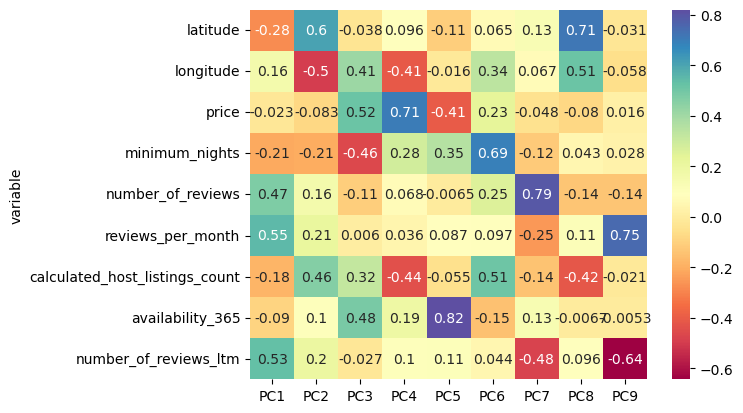

In [28]:
ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()
# can browse characteristics of each principal component

In [29]:
pca.transform(NYC_st)

array([[-1.20549042, -2.15090642, -1.31338548, ..., -0.0366344 ,
         0.95941482, -0.12635375],
       [ 1.28409385, -0.263147  ,  0.52524093, ...,  1.87176117,
        -0.45949847,  0.01677716],
       [ 1.55770296, -0.17472013,  0.52487615, ...,  1.90533864,
        -0.45944711,  0.02524577],
       ...,
       [-2.10424884,  2.56144992,  1.33790983, ...,  0.03119469,
         0.04461682, -0.02285919],
       [-0.50891379, -0.05503264, -0.29555635, ..., -0.03511681,
         0.19378192,  0.61518854],
       [ 0.07897334, -1.33665454, -0.19386999, ..., -0.16702927,
         0.23073187,  0.56535372]], shape=(420, 9))

In [30]:
scores = pca.transform(NYC_st).transpose()